# 09. Pronóstico financiero de Grupo Éxito para 2026

## Objetivo

Generar pronósticos trimestrales para los ingresos operacionales, la utilidad bruta, el EBITDA recurrente y el resultado neto de Grupo Éxito durante 2026.

Se utilizarán los modelos seleccionados en la evaluación del notebook 08:

- **Ingresos operacionales:** baseline estacional.
- **Utilidad bruta:** baseline estacional.
- **EBITDA recurrente:** Holt-Winters.
- **Resultado neto:** suavizamiento exponencial simple.

Los pronósticos se generarán utilizando la información histórica disponible hasta el cuarto trimestre de 2025. Posteriormente, se compararán con los valores reales disponibles para 2026, utilizando métricas de error para evaluar su precisión.

Los pronósticos originales se conservarán sin incorporar información real de 2026 al entrenamiento, con el fin de mantener una comparación válida.

In [15]:
# Carga de los datos históricos originales para hacer uso de las 24 observaciones 

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing
)

# Identificar la raíz del proyecto
RAIZ_PROYECTO = Path.cwd()

if RAIZ_PROYECTO.name == "notebooks":
    RAIZ_PROYECTO = RAIZ_PROYECTO.parent

RUTA_BRONZE = (
    RAIZ_PROYECTO
    / "data"
    / "Bronze"
    / "informe_resultados_exito.xlsx"
)

print("Archivo:", RUTA_BRONZE)
print("¿Existe el archivo?", RUTA_BRONZE.exists())

if not RUTA_BRONZE.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {RUTA_BRONZE}"
    )

df_historico = pd.read_excel(RUTA_BRONZE)

df_historico["fecha"] = pd.to_datetime(
    df_historico["fecha"]
)

df_historico = (
    df_historico
    .sort_values("fecha")
    .reset_index(drop=True)
)

variables_objetivo = [
    "ingresos",
    "utilidad_bruta",
    "ebitda_recurrente",
    "resultado_neto"
]

print("Dimensiones:", df_historico.shape)
print(
    "Periodo:",
    df_historico["fecha"].min(),
    "a",
    df_historico["fecha"].max()
)

display(df_historico.head())
display(df_historico.tail())

Archivo: c:\Users\USUARIO\Documents\GitHub\Sistema-de-Pronostico-Financiero-Grupo-Exito\data\Bronze\informe_resultados_exito.xlsx
¿Existe el archivo? True
Dimensiones: (24, 7)
Periodo: 2020-03-31 00:00:00 a 2025-12-31 00:00:00


,año,trimestre,fecha,ingresos,utilidad_bruta,ebitda_recurrente,resultado_neto
0,2020,1,2020-03-31,4052431,1001122,262832,21987
1,2020,2,2020-06-30,3688456,911875,299143,12787
2,2020,3,2020-09-30,3649939,901871,249457,51814
3,2020,4,2020-12-31,4345013,1142061,460429,144284
4,2021,1,2021-03-31,3819172,1016535,306694,84957


,año,trimestre,fecha,ingresos,utilidad_bruta,ebitda_recurrente,resultado_neto
19,2024,4,2024-12-31,6288024,1624970,638210,146117
20,2025,1,2025-03-31,5404642,1382773,371148,93147
21,2025,2,2025-06-30,5208469,1335783,452242,146865
22,2025,3,2025-09-30,5228905,1312056,448017,142905
23,2025,4,2025-12-31,6166344,1612428,670615,209191


## 2. Generación de pronósticos para 2026

Se entrenan los modelos seleccionados con los datos históricos hasta 2025-T4. Los pronósticos se generan para los cuatro trimestres de 2026 sin incorporar valores reales de ese año al entrenamiento.

Para ingresos y utilidad bruta se utiliza el baseline estacional. Para EBITDA recurrente se utiliza Holt-Winters y para resultado neto, suavizamiento exponencial simple.

In [16]:
# Preparación del conjunto de entrenamiento

# Separar el histórico disponible hasta el cierre de 2025
df_train = df_historico[
    df_historico["fecha"].dt.year <= 2025
].copy()

df_train = (
    df_train
    .sort_values("fecha")
    .reset_index(drop=True)
)

# Verificaciones de calidad
if df_train[variables_objetivo].isna().any().any():
    raise ValueError(
        "Hay valores faltantes en las variables financieras."
    )

if len(df_train) != 24:
    raise ValueError(
        f"Se esperaban 24 registros históricos y hay {len(df_train)}."
    )

print("Observaciones de entrenamiento:", len(df_train))
print("Último periodo:", df_train["fecha"].max())


Observaciones de entrenamiento: 24
Último periodo: 2025-12-31 00:00:00


In [17]:
# Cálculo de los 4 pronósticos para 2026 usando el mejor modelo por variable

# Trimestres que se van a pronosticar
fechas_futuras = pd.date_range(
    start="2026-03-31",
    periods=4,
    freq="QE"
)

df_forecast_2026 = pd.DataFrame({
    "fecha": fechas_futuras,
    "año": fechas_futuras.year,
    "trimestre": fechas_futuras.quarter
})

# 1. Ingresos: baseline estacional
serie_ingresos = df_train["ingresos"].astype(float).to_numpy()

pronostico_ingresos = serie_ingresos[-4:]

df_forecast_2026["ingresos"] = np.tile(
    pronostico_ingresos, 1
)

# 2. Utilidad bruta: baseline estacional
serie_utilidad = (
    df_train["utilidad_bruta"].astype(float).to_numpy()
)

df_forecast_2026["utilidad_bruta"] = serie_utilidad[-4:]

# 3. EBITDA recurrente: Holt-Winters
serie_ebitda = df_train["ebitda_recurrente"].astype(float)

modelo_ebitda = ExponentialSmoothing(
    serie_ebitda,
    trend="add",
    seasonal="add",
    seasonal_periods=4,
    initialization_method="estimated"
).fit(optimized=True)

df_forecast_2026["ebitda_recurrente"] = (
    modelo_ebitda.forecast(4).to_numpy()
)

# 4. Resultado neto: suavizamiento exponencial simple
serie_resultado_neto = (
    df_train["resultado_neto"].astype(float)
)

modelo_resultado_neto = SimpleExpSmoothing(
    serie_resultado_neto,
    initialization_method="estimated"
).fit()

df_forecast_2026["resultado_neto"] = (
    modelo_resultado_neto.forecast(4).to_numpy()
)

# Etiquetas de trimestre
df_forecast_2026["periodo"] = (
    df_forecast_2026["año"].astype(str)
    + "-T"
    + df_forecast_2026["trimestre"].astype(str)
)

display(df_forecast_2026.round(2))


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_20000\1154659552.py:68: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_forecast_2026.round(2))


,fecha,año,trimestre,ingresos,utilidad_bruta,ebitda_recurrente,resultado_neto,periodo
0,2026-03-31,2026,1,5404642.0,1382773.0,472322.52,165828.57,2026-T1
1,2026-06-30,2026,2,5208469.0,1335783.0,498189.59,165828.57,2026-T2
2,2026-09-30,2026,3,5228905.0,1312056.0,496621.36,165828.57,2026-T3
3,2026-12-31,2026,4,6166344.0,1612428.0,704357.92,165828.57,2026-T4


In [18]:
# Guardado del pronóstico de 2026 en la carpeta gold

RUTA_GOLD = RAIZ_PROYECTO / "data" / "Gold"
RUTA_GOLD.mkdir(parents=True, exist_ok=True)

RUTA_PRONOSTICOS = (
    RUTA_GOLD / "pronosticos_grupo_exito_2026.csv"
)

df_forecast_2026.to_csv(
    RUTA_PRONOSTICOS,
    index=False,
    encoding="utf-8-sig"
)

print("Pronósticos guardados en:", RUTA_PRONOSTICOS)


Pronósticos guardados en: c:\Users\USUARIO\Documents\GitHub\Sistema-de-Pronostico-Financiero-Grupo-Exito\data\Gold\pronosticos_grupo_exito_2026.csv


## 3. Comparación con los valores reales de 2026

Se comparan los pronósticos generados con los resultados reales publicados para el primer y segundo trimestre de 2026. Los modelos no se reentrenan con estos datos, de modo que la comparación evalúa el desempeño de los pronósticos originales.

In [19]:
# Cargar los datos reales de 2026

ruta_reales = "../data/Bronze/informe_resultados_exito_2026.xlsx"

df_reales_2026 = pd.read_excel(ruta_reales)

# Unir los datos reales con los pronósticos por año y trimestre
df_comparacion = df_reales_2026.merge(
    df_forecast_2026,
    on=["año", "trimestre"],
    how="left",
    suffixes=("_real", "_pronostico"),
    validate="one_to_one"
)

# Crear nuevamente la columna periodo
df_comparacion["periodo"] = (
    df_comparacion["año"].astype(str)
    + "-T"
    + df_comparacion["trimestre"].astype(str)
)

# Verificar que la unión se haya realizado correctamente
columnas = [
    "periodo",
    "ingresos_real",
    "ingresos_pronostico",
    "utilidad_bruta_real",
    "utilidad_bruta_pronostico",
    "ebitda_recurrente_real",
    "ebitda_recurrente_pronostico",
    "resultado_neto_real",
    "resultado_neto_pronostico"
]

display(df_comparacion[columnas])

,periodo,ingresos_real,ingresos_pronostico,utilidad_bruta_real,utilidad_bruta_pronostico,ebitda_recurrente_real,ebitda_recurrente_pronostico,resultado_neto_real,resultado_neto_pronostico
0,2026-T1,5457857,5404642.0,1424318,1382773.0,430780,472322.515575,159622,165828.565924
1,2026-T2,5299168,5208469.0,1356402,1335783.0,499971,498189.589161,156186,165828.565924


In [20]:
# Creación de métricas

metricas_2026 = []

for variable in variables_objetivo:
    datos = df_comparacion_detalle[
        df_comparacion_detalle["variable"] == variable
    ]

    errores = datos["error"].to_numpy()
    errores_absolutos = datos["error_absoluto"].to_numpy()

    metricas_2026.append({
        "variable": variable,
        "MAE": np.mean(errores_absolutos),
        "RMSE": np.sqrt(np.mean(errores ** 2)),
        "MAPE_pct": (
            np.nan
            if variable == "resultado_neto"
            else datos["error_porcentual"].mean()
        ),
        "trimestres_evaluados": len(datos)
    })

df_metricas_2026 = pd.DataFrame(metricas_2026)

display(df_metricas_2026.round(2))


,variable,MAE,RMSE,MAPE_pct,trimestres_evaluados
0,ingresos,71957.00,74357.73,1.34,2
1,utilidad_bruta,31082.00,32795.81,2.22,2
2,ebitda_recurrente,21661.96,29401.99,5.00,2
3,resultado_neto,7924.57,8108.65,NaN,2


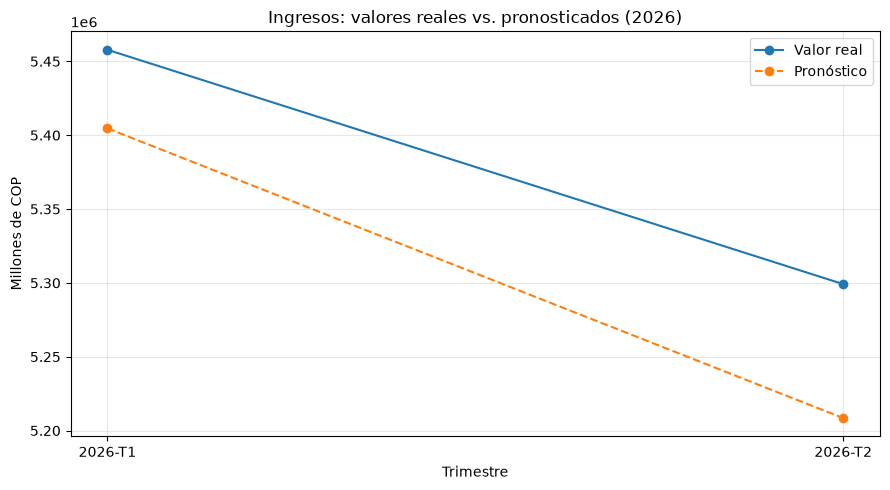

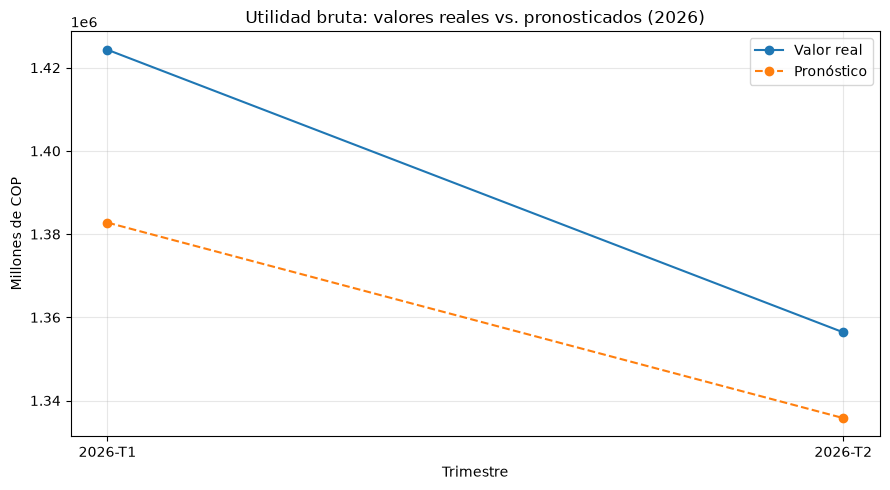

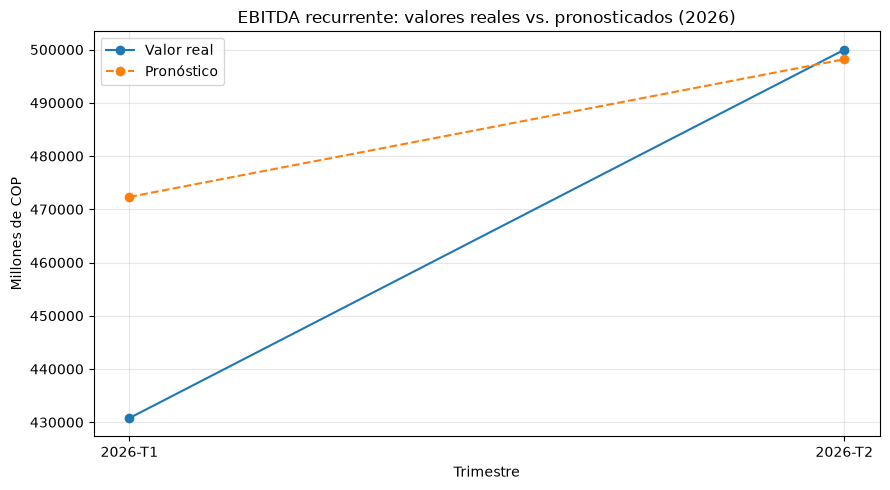

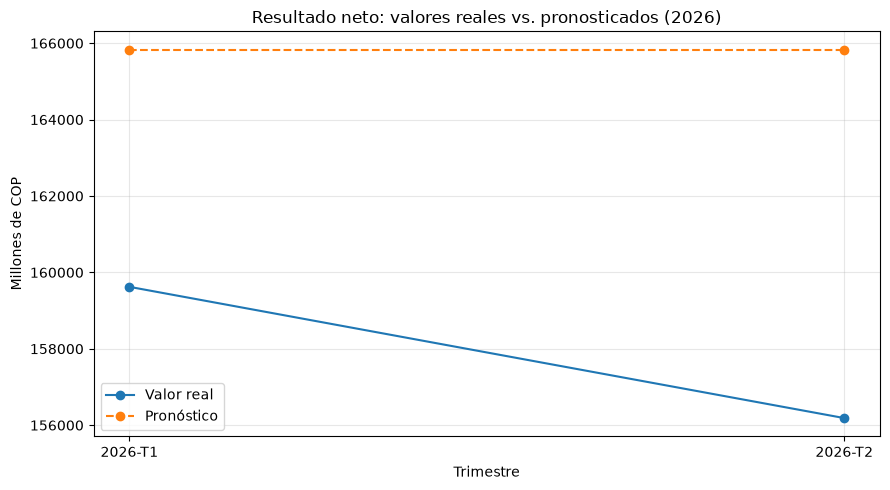

In [21]:
# Creación de gráficos comparativos para cada variable financiera

import matplotlib.pyplot as plt

variables = {
    "ingresos": "Ingresos",
    "utilidad_bruta": "Utilidad bruta",
    "ebitda_recurrente": "EBITDA recurrente",
    "resultado_neto": "Resultado neto"
}

for variable, nombre in variables.items():
    plt.figure(figsize=(9, 5))

    plt.plot(
        df_comparacion["periodo"],
        df_comparacion[f"{variable}_real"],
        marker="o",
        label="Valor real"
    )

    plt.plot(
        df_comparacion["periodo"],
        df_comparacion[f"{variable}_pronostico"],
        marker="o",
        linestyle="--",
        label="Pronóstico"
    )

    plt.title(f"{nombre}: valores reales vs. pronosticados (2026)")
    plt.xlabel("Trimestre")
    plt.ylabel("Millones de COP")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [22]:
ruta_gold = Path("../data/Gold")
ruta_gold.mkdir(parents=True, exist_ok=True)

# Guardar detalle de valores reales y pronosticados
df_comparacion.to_csv(
    ruta_gold / "comparacion_real_vs_pronostico_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar métricas de evaluación
df_metricas_2026.to_csv(
    ruta_gold / "metricas_evaluacion_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivos guardados correctamente en:", ruta_gold.resolve())

Archivos guardados correctamente en: C:\Users\USUARIO\Documents\GitHub\Sistema-de-Pronostico-Financiero-Grupo-Exito\data\Gold


# 10. Conclusiones de la evaluación de pronósticos 2026

## Objetivo

Evaluar el desempeño de los modelos de pronóstico desarrollados con información financiera trimestral histórica de Grupo Éxito, comparando las predicciones de 2026 con los valores reales disponibles.

## Resultados de la evaluación

La evaluación se realizó con los datos reales correspondientes al primer y segundo trimestre de 2026. Se compararon cuatro indicadores financieros: ingresos, utilidad bruta, EBITDA recurrente y resultado neto.

Las métricas MAE y RMSE permitieron cuantificar la magnitud de los errores de pronóstico. El MAPE se utilizó de acuerdo con los criterios metodológicos definidos para cada variable.

## Consideraciones metodológicas

- La evaluación comprende únicamente dos trimestres, por lo que los resultados son preliminares.
- Los resultados obtenidos no garantizan que los modelos mantengan el mismo desempeño en los trimestres siguientes.
- El pronóstico del resultado neto mediante suavizamiento exponencial simple produce valores constantes, característica del modelo que debe considerarse al interpretar sus resultados.
- Los pronósticos originales se conservan para asegurar la trazabilidad de la evaluación.
- Los trimestres tercero y cuarto de 2026 permanecen pendientes de validación hasta disponer de los resultados reales.

## Próximos pasos

1. Incorporar los resultados reales de T3 y T4 cuando estén disponibles.
2. Actualizar las métricas de evaluación con los nuevos datos.
3. Comparar el desempeño acumulado de los modelos.
4. Documentar las limitaciones derivadas del tamaño reducido de la serie histórica.

## Conclusión general

El proyecto permite establecer un proceso reproducible de preparación de datos, ingeniería de características, modelado, evaluación y pronóstico financiero. La comparación con los valores reales de 2026 constituye una primera validación práctica. Se requiere ampliar el período de evaluación antes de establecer conclusiones definitivas sobre la precisión de los modelos.